# Medical Imaging × Glitch Art — Data Prep + Planning

In [2]:
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/data_utils.py" -O data_utils.py
!wget -q "https://github.com/PSAM-5020-2026F-A/5020-utils/raw/main/src/image_utils.py" -O image_utils.py

In [3]:
import os

import matplotlib.pyplot as plt
import pandas as pd
import PIL.Image as PImage

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

from image_utils import get_pixels, make_image

SMALL = 128

In [4]:
# 1. medical sample
med_df = pd.read_csv("data/medical_index.csv")

print(med_df.shape)
display(med_df[["dataset", "label"]].value_counts().sort_index())

(280, 9)


dataset          label     
brain_ct_color   aneurysm      40
                 cancer        40
                 tumor         40
brain_tumor_mri  glioma        40
                 meningioma    40
                 notumor       40
                 pituitary     40
Name: count, dtype: int64

### Original sizes + colour modes

Before resizing, the images were not all the same. `mode` = how the colour is stored: `L` = grayscale, `RGB` = colour.

In [5]:
for dataset in med_df["dataset"].unique():
  ds_df = med_df[med_df["dataset"] == dataset]
  print("=====", dataset)
  display(ds_df[["orig_width", "orig_height"]].describe().round(0))
  display(ds_df["orig_mode"].value_counts())

===== brain_ct_color


,orig_width,orig_height
count,120.0,120.0
mean,512.0,512.0
std,0.0,0.0
min,512.0,512.0
25%,512.0,512.0
50%,512.0,512.0
75%,512.0,512.0
max,512.0,512.0


orig_mode
RGB    120
Name: count, dtype: int64

===== brain_tumor_mri


,orig_width,orig_height
count,160.0,160.0
mean,451.0,454.0
std,127.0,123.0
min,173.0,192.0
25%,442.0,444.0
50%,512.0,512.0
75%,512.0,512.0
max,1024.0,1024.0


orig_mode
RGB     89
L       70
RGBA     1
Name: count, dtype: int64

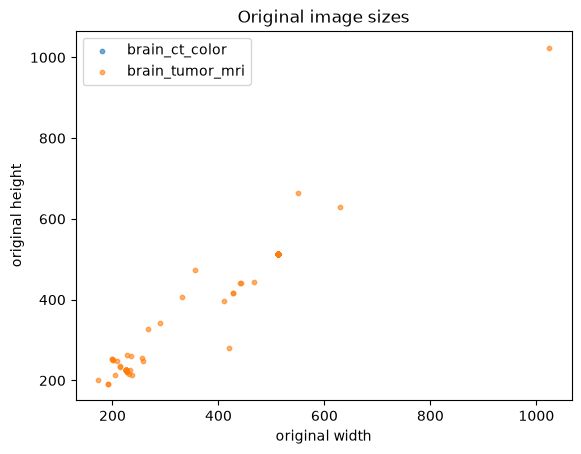

In [6]:
for dataset in med_df["dataset"].unique():
  ds_df = med_df[med_df["dataset"] == dataset]
  plt.scatter(ds_df["orig_width"], ds_df["orig_height"], s=10, alpha=0.6, label=dataset)

plt.xlabel("original width")
plt.ylabel("original height")
plt.title("Original image sizes")
plt.legend()
plt.show()

gah i need to compile things... 